# 02 · Kaplan-Meier e testes log-rank / Kaplan-Meier & log-rank tests

Estimativa **não paramétrica** da curva de retenção $S(t) = P(\text{tenure} > t)$ e comparação
entre grupos sem impor nenhuma forma funcional.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


## Curva de retenção geral / Overall retention curve

Median tenure (KM): 51.0 months


,survival,ci_lower,ci_upper
tenure_months,,,
3,0.980,0.970,0.987
6,0.940,0.924,0.953
12,0.856,0.833,0.876
24,0.697,0.666,0.725
36,0.607,0.574,0.638
60,0.429,0.391,0.465


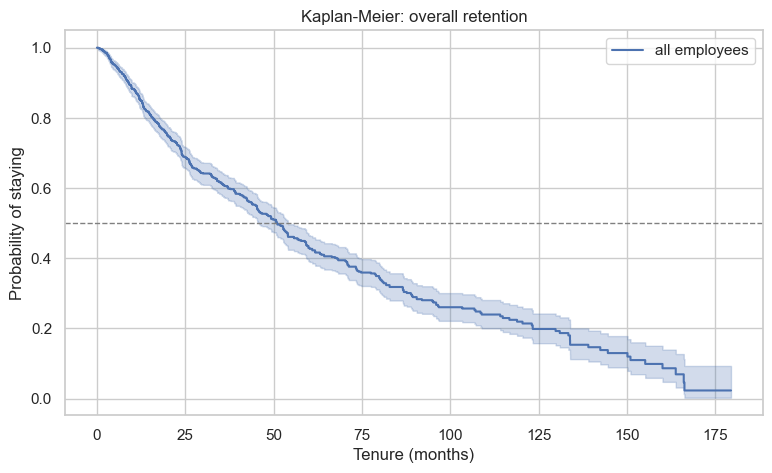

In [2]:
kmf = nonparametric.fit_km(df)
fig, ax = plt.subplots(figsize=(9, 5))
kmf.plot_survival_function(ax=ax, at_risk_counts=False)
ax.axhline(0.5, ls="--", c="grey", lw=1)
ax.set(xlabel="Tenure (months)", ylabel="Probability of staying", title="Kaplan-Meier: overall retention")
fig.savefig(config.FIGURES_DIR / "02_km_overall.png", dpi=120, bbox_inches="tight")

print(f"Median tenure (KM): {kmf.median_survival_time_:.1f} months")
nonparametric.survival_at(kmf, [3, 6, 12, 24, 36, 60])

**Leitura:** `survival` no mês 12 = probabilidade estimada de um funcionário ainda estar na empresa
após 1 ano. `1 - survival` é o turnover acumulado.

## Risco acumulado / Cumulative hazard (Nelson-Aalen)

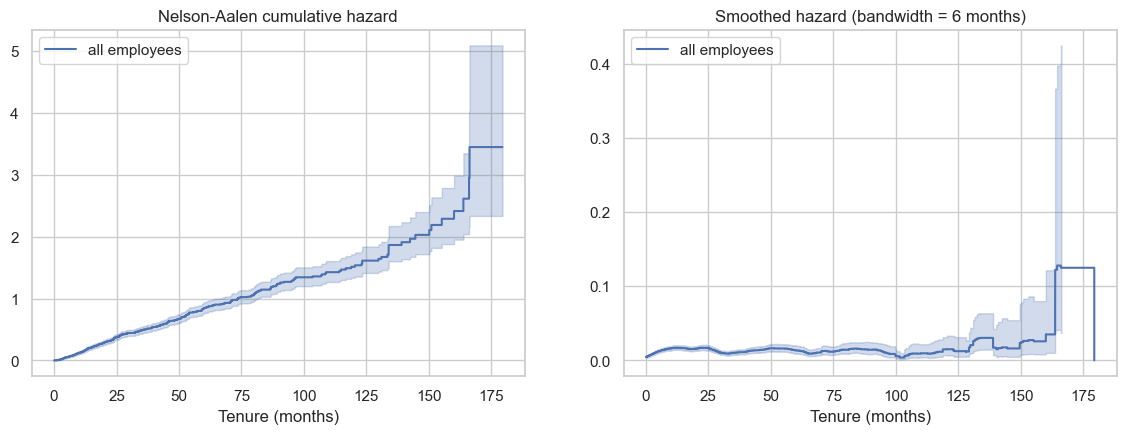

In [3]:
naf = nonparametric.fit_na(df)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
naf.plot_cumulative_hazard(ax=axes[0])
axes[0].set(title="Nelson-Aalen cumulative hazard", xlabel="Tenure (months)")
naf.plot_hazard(bandwidth=6, ax=axes[1])
axes[1].set(title="Smoothed hazard (bandwidth = 6 months)", xlabel="Tenure (months)")
fig.savefig(config.FIGURES_DIR / "02_hazard.png", dpi=120, bbox_inches="tight")

A forma do **hazard** orienta a escolha do modelo paramétrico (notebook 04): hazard decrescente
sugere Weibull com ρ < 1; hazard que sobe e depois cai sugere log-normal ou log-logística.

## Comparação entre grupos / Group comparisons

In [4]:
# discretise numerics into quartiles so they can be compared with log-rank too
dfg = df.copy()
for col in config.NUMERIC_COLS:
    dfg[f"{col}_q"] = pd.qcut(dfg[col], 4, duplicates="drop").astype(str)
group_cols = config.CATEGORICAL_COLS + [f"{c}_q" for c in config.NUMERIC_COLS]

lr = nonparametric.logrank_table(dfg, group_cols)
lr["significant_5%"] = lr["p_value"] < 0.05
lr

,variable,n_groups,test_statistic,p_value,significant_5%
0,industry,16,64.190,0.000,True
1,greywage,2,22.648,0.000,True
2,age_q,4,17.269,0.001,True
3,traffic,8,23.641,0.001,True
4,way,3,12.595,0.002,True
5,extraversion_q,4,13.148,0.004,True
6,profession,15,30.195,0.007,True
7,selfcontrol_q,4,9.040,0.029,True
8,anxiety_q,4,7.697,0.053,False
9,gender,2,2.214,0.137,False


> ⚠️ São muitos testes simultâneos: alguns p < 0,05 surgem por acaso. Trate isso como triagem
> exploratória; o efeito ajustado de cada variável vem do Cox (notebook 03).

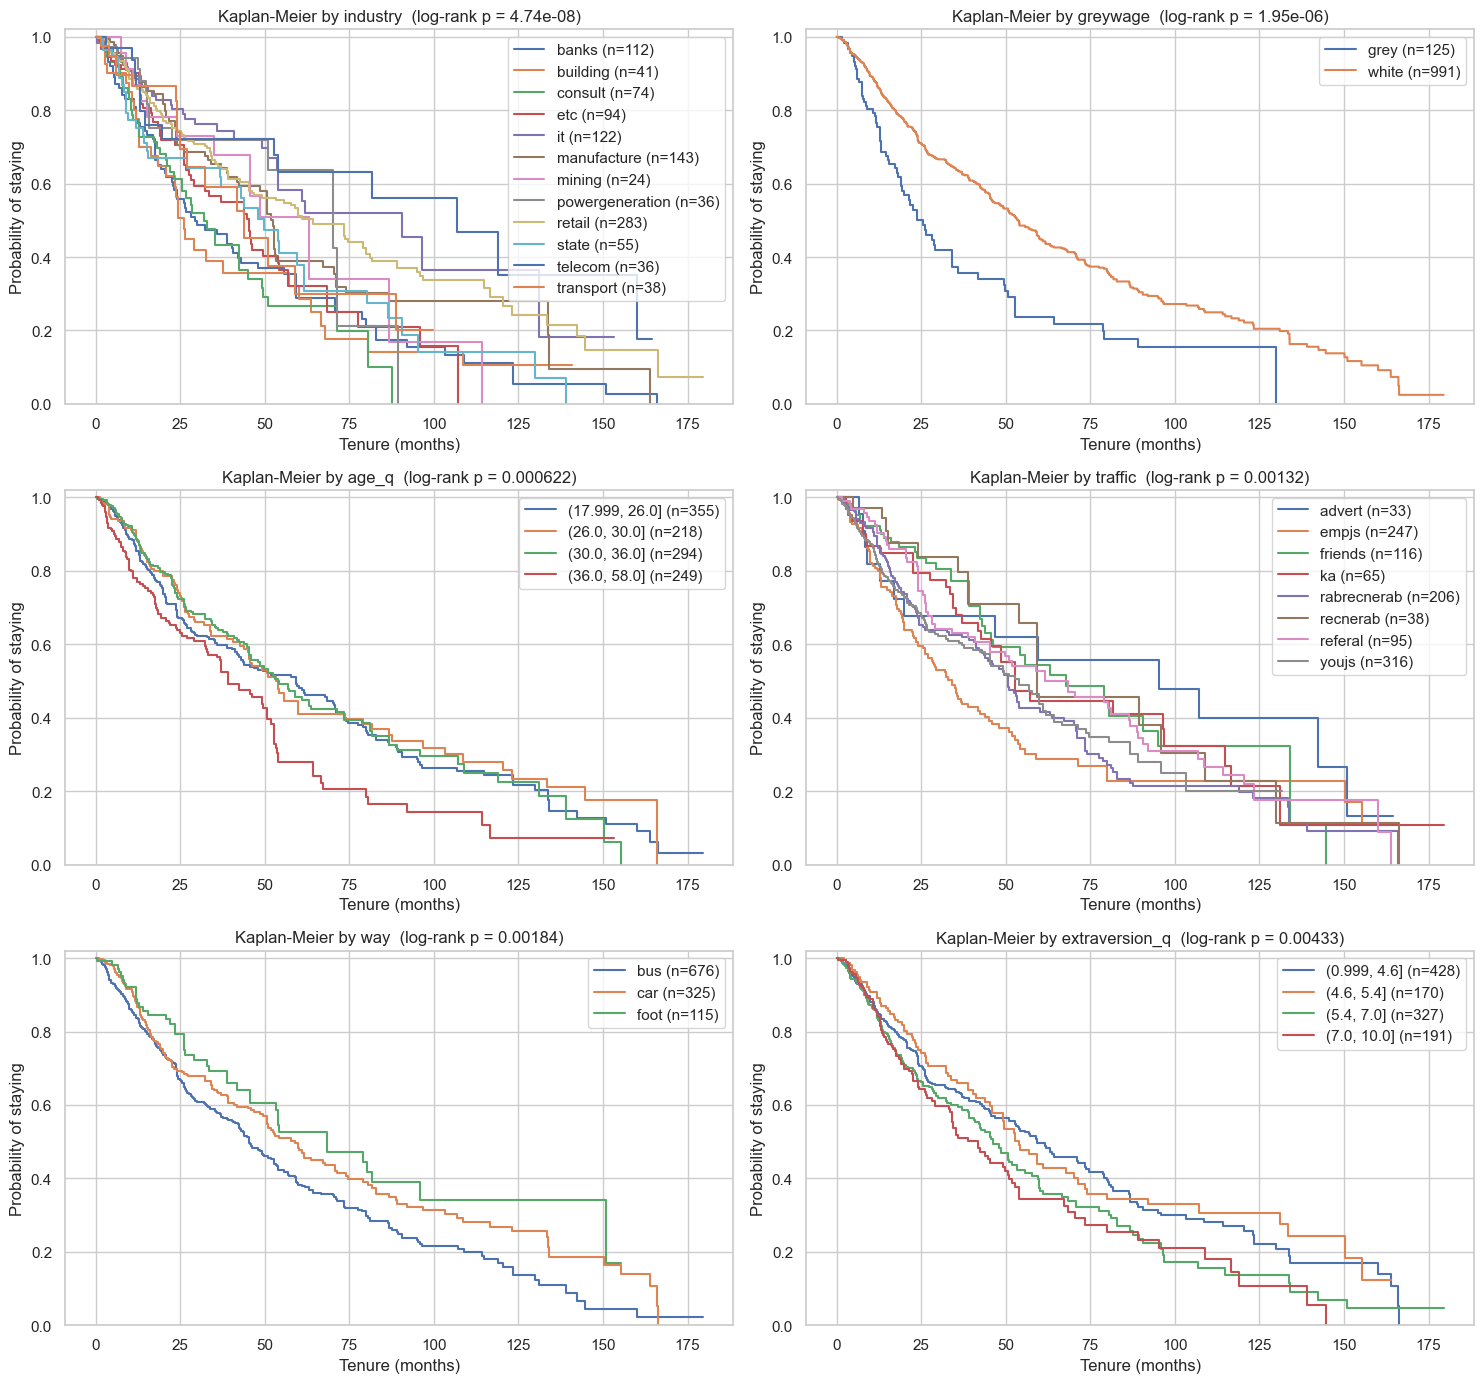

In [5]:
top = lr.head(6)["variable"].tolist()
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
for ax, col in zip(axes.ravel(), top):
    nonparametric.plot_km_by_group(dfg, col, ax=ax, min_n=config.MIN_CATEGORY_FREQ)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_km_by_group.png", dpi=120, bbox_inches="tight")

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._